# 09: Muon-catalyzed fusion, the gap that is already small

Notebook 06 showed muonic compression (0.36 pm) gives fusion rates of 10⁷–10¹³ s⁻¹: the physics works at room temperature. The obstacle is the **energy balance**: each muon costs more energy to make than its fusions release. This notebook quantifies the gap and each lever on it.

**Standard cycle model.** A muon catalyses fusions at the cycling rate φλ_c (φ = density relative to liquid hydrogen) until it decays (λ₀ = 1/2.197 μs) or sticks to an alpha particle (probability ω_s per fusion):

$$X = \frac{1}{\lambda_0/(\varphi\lambda_c) + \omega_s}$$

**Inputs (confirmed at abstract/secondary level):** ~150 fusions per muon (LAMPF); effective sticking 0.3–0.5% (SIN 0.45%); cycling rate ~10⁸ s⁻¹ (1.6×10⁸ at 700 atm in 1986 data); muon cost ~5 GeV (2026 review), reducible ~2.5× by design (Kelly et al. 2021); published Q ≈ 0.53 (fusion only) and 0.65–0.78 with breeding heat, ~14% electrical out/in.

In [1]:
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"font.size":10,"axes.titlesize":11})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, INK, MUTED = "#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#0b0b0b","#52514e"
lam0 = 1/2.197e-6                 # muon decay rate, 1/s
E_F = 17.59                       # MeV per d-t fusion
E_BLANKET = 17.59 + 4.8           # MeV thermal per fusion incl. 6Li(n,alpha)t breeding in a blanket
LAMC0 = lam0/(1.2*(1/150 - 0.0045))      # cycling rate calibrated so X = 150 at omega_s = 0.45%, phi = 1.2
def X(omega_s, lam_c=None, phi=1.2):
    lam_c = LAMC0 if lam_c is None else lam_c
    return 1/(lam0/(phi*lam_c) + omega_s)
def gains(Xv, E_mu_MeV, eta_th=0.40, eta_acc=0.40, blanket=True):
    Ef = E_BLANKET if blanket else E_F
    Q_sci = Xv*Ef/E_mu_MeV
    Q_el = eta_th*Xv*Ef/(E_mu_MeV/eta_acc)          # electricity out / wall-plug electricity into the muon source
    return Q_sci, Q_el
X_now = 150
for blanket in [False, True]:
    q, e = gains(X_now, 5000, blanket=blanket)
    print(f"X = 150, 5 GeV/muon, {'with' if blanket else 'no'} blanket: Q_sci = {q:.2f}, electrical gain = {e:.2f}")
print(f"\ncalibrated cycling rate lam_c = {LAMC0:.2e} /s (1986 data: 1.6e8 at 700 atm) -> X = {X(0.0045):.0f} at omega_s = 0.45%")

X = 150, 5 GeV/muon, no blanket: Q_sci = 0.53, electrical gain = 0.08
X = 150, 5 GeV/muon, with blanket: Q_sci = 0.67, electrical gain = 0.11

calibrated cycling rate lam_c = 1.75e+08 /s (1986 data: 1.6e8 at 700 atm) -> X = 150 at omega_s = 0.45%


The model reproduces the published numbers: Q ≈ 0.53 (fusion only), 0.67 with breeding heat (published 0.65–0.78), and an electrical gain of ~0.11 at 40% thermal and 40% accelerator efficiency (published ~14%).

## 1. How far from breakeven?

In [2]:
def factor_needed(Q): return 1/Q
q_sci, q_el = gains(X_now, 5000)
print(f"scientific breakeven (Q_sci = 1): x{factor_needed(q_sci):.1f} away  ({np.log10(factor_needed(q_sci)):.2f} orders)")
print(f"net electricity (gain = 1):       x{factor_needed(q_el):.1f} away  ({np.log10(factor_needed(q_el)):.2f} orders)")
print(f"commercial-scale (gain ~ 4, for recirculating power and plant losses): x{4/q_el:.0f} away ({np.log10(4/q_el):.2f} orders)")
print("\ncompare: cold fusion at rest, notebooks 01-08: 15 to 114 ORDERS of magnitude")

scientific breakeven (Q_sci = 1): x1.5 away  (0.17 orders)
net electricity (gain = 1):       x9.3 away  (0.97 orders)
commercial-scale (gain ~ 4, for recirculating power and plant losses): x37 away (1.57 orders)

compare: cold fusion at rest, notebooks 01-08: 15 to 114 ORDERS of magnitude


## 2. Levers

In [3]:
levers = [
  ("today", dict(omega=0.0045, lam_c=None, phi=1.2, Emu=5000, eta_th=0.40, eta_acc=0.40)),
  ("muon cost / 2.5 (Kelly et al. design)", dict(omega=0.0045, lam_c=None, phi=1.2, Emu=2000, eta_th=0.40, eta_acc=0.40)),
  ("sticking halved (0.225%)", dict(omega=0.00225, lam_c=None, phi=1.2, Emu=5000, eta_th=0.40, eta_acc=0.40)),
  ("cycling rate x3 (high density/temperature)", dict(omega=0.0045, lam_c=3*LAMC0, phi=1.2, Emu=5000, eta_th=0.40, eta_acc=0.40)),
  ("better conversion (eta_th 0.5, eta_acc 0.6)", dict(omega=0.0045, lam_c=None, phi=1.2, Emu=5000, eta_th=0.50, eta_acc=0.60)),
  ("cost /2.5 + sticking /2", dict(omega=0.00225, lam_c=None, phi=1.2, Emu=2000, eta_th=0.40, eta_acc=0.40)),
  ("cost /2.5 + sticking /2 + cycling x3", dict(omega=0.00225, lam_c=3*LAMC0, phi=1.2, Emu=2000, eta_th=0.40, eta_acc=0.40)),
  ("all of the above + better conversion", dict(omega=0.00225, lam_c=3*LAMC0, phi=1.2, Emu=2000, eta_th=0.50, eta_acc=0.60)),
]
print(f"{'scenario':46s} {'X':>6s} {'Q_sci':>7s} {'elec. gain':>11s}")
for name, p in levers:
    Xv = X(p["omega"], p["lam_c"], p["phi"])
    q, e = gains(Xv, p["Emu"], p["eta_th"], p["eta_acc"])
    print(f"{name:46s} {Xv:6.0f} {q:7.2f} {e:11.2f}")

scenario                                            X   Q_sci  elec. gain
today                                             150    0.67        0.11
muon cost / 2.5 (Kelly et al. design)             150    1.68        0.27
sticking halved (0.225%)                          226    1.01        0.16
cycling rate x3 (high density/temperature)        191    0.86        0.14
better conversion (eta_th 0.5, eta_acc 0.6)       150    0.67        0.20
cost /2.5 + sticking /2                           226    2.53        0.41
cost /2.5 + sticking /2 + cycling x3              336    3.77        0.60
all of the above + better conversion              336    3.77        1.13


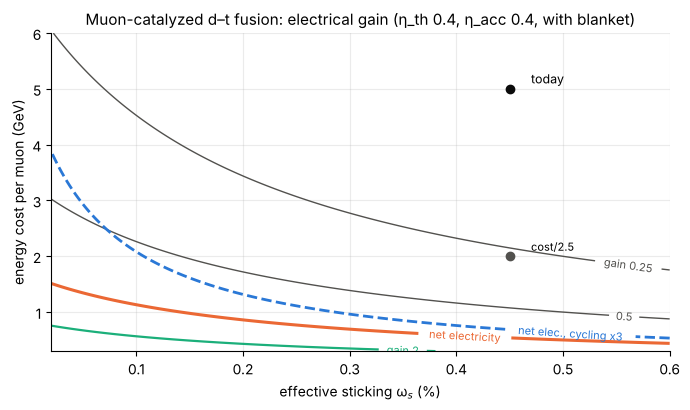

In [4]:
om = np.linspace(0.0002, 0.006, 300); Em = np.linspace(300, 6000, 300)
O, EM = np.meshgrid(om, Em)
_, G = gains(X(O, None, 1.2), EM)
_, G3 = gains(X(O, 3*LAMC0, 1.2), EM)
fig, ax = plt.subplots(figsize=(7, 4.2))
cs = ax.contour(O*100, EM/1000, G, levels=[0.25, 0.5, 1, 2], colors=[MUTED, MUTED, ORANGE, AQUA], linewidths=[1, 1, 2.2, 1.6])
ax.clabel(cs, fmt={0.25: "gain 0.25", 0.5: "0.5", 1: "net electricity", 2: "gain 2"}, fontsize=8)
cs3 = ax.contour(O*100, EM/1000, G3, levels=[1], colors=[BLUE], linewidths=2, linestyles="--")
ax.clabel(cs3, fmt={1: "net elec., cycling x3"}, fontsize=8)
ax.scatter([0.45], [5.0], color=INK, zorder=3); ax.text(0.47, 5.1, "today", fontsize=9)
ax.scatter([0.45], [2.0], color=MUTED, zorder=3); ax.text(0.47, 2.1, "cost/2.5", fontsize=8)
ax.set_xlabel("effective sticking ω$_s$ (%)"); ax.set_ylabel("energy cost per muon (GeV)")
ax.set_title("Muon-catalyzed d–t fusion: electrical gain (η_th 0.4, η_acc 0.4, with blanket)")
plt.tight_layout(); plt.savefig("../figures/09_muon_balance.png", dpi=130); plt.show()

## 3. Verdict

* **Distance:** ~1.5× from scientific breakeven (with breeding heat; ~1.9× without) and **~9× from net electricity**, i.e. **about one order of magnitude**, against 15–114 orders for fusion at rest in metals. Muon-catalyzed fusion is the only room-temperature fusion route where the gap is engineering-sized.
* **No single lever closes it.** Cheaper muons (/2.5) give the largest single gain and alone pass *scientific* breakeven. Net electricity needs **all four together**: cheaper muons, halved sticking, a 3× faster cycle *and* better conversion efficiencies (table above). Each is plausible on its own; needing all of them at once is why it hasn't happened.
* **The physics unknowns are exactly what MuFusE (PSI, 2024–2026) is measuring:** cycling rate and sticking at densities above 1.45× liquid hydrogen and temperatures above 400 K. The measured density dependence of sticking has been an unexplained puzzle since the 1980s. If sticking keeps falling at higher density, the "sticking halved" lever may be real.
* **Engineering unknowns:** muon production efficiency (target, pion capture, decay channel), accelerator wall-plug efficiency, tritium handling.

**What would move this project's conclusion:** a MuFusE result showing sticking ≲0.25% or cycling ≳3×10⁸ s⁻¹ at high density. That's worth watching; it's the one live path to room-temperature fusion energy.

**Status:** inputs as listed in the header (abstract/secondary level); blanket thermal energy per fusion 22.4 MeV assumes ⁶Li(n,α)t capture of every neutron; efficiencies are typical-range assumptions.